# 1. CHARGEMENT DES DONNÉES

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# ==========================================
# 1. CHARGEMENT DES DONNÉES
# ==========================================
# Charger le fichier MAT téléchargé
chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\sAINS\98.mat"
mat_data = loadmat(chemin)  

# Extraire le signal vibratoire (ajuster le nom de la clé si nécessaire)
# Dans votre fichier, la variable s'appelle 'X098_DE_time'
signal = mat_data['X098_DE_time'].flatten()

# ==========================================
# 2. CONFIGURATION DES PARAMÈTRES DU SIGNAL
# ==========================================
# Fréquence d'échantillonnage théorique (en Hz)
# Note : 12000 Hz est la valeur standard pour les données CWRU (Drive End data)
fs = 12000  

# Nombre de points dans le signal
N = len(signal)

# Durée totale du signal en secondes
duree = N / fs

print(f"Nombre de points de mesure : {N}")
print(f"Durée du signal analysé : {duree:.2f} secondes")

Nombre de points de mesure : 483903
Durée du signal analysé : 40.33 secondes


AFFICHAGE SIGNAL

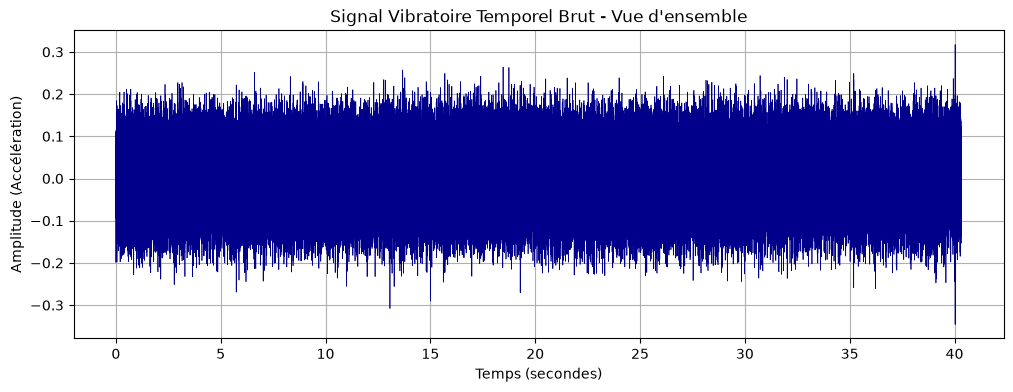

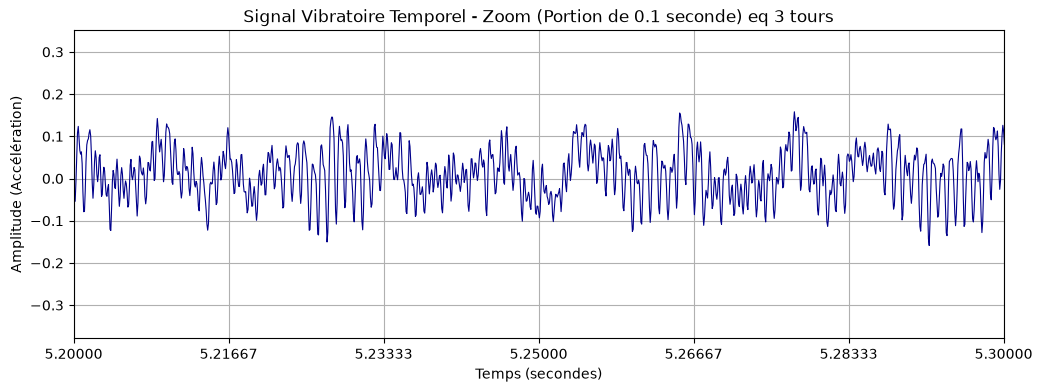

In [13]:
# 3. Création du vecteur temps (en secondes)
# Chaque point de mesure correspond à un instant précis : t = indice / fs
temps = np.arange(N) / fs

# ========================================================
# INSTRUCTION POUR AFFICHER LE SIGNAL TEMPOREL EN ENTIER
# ========================================================
plt.figure(figsize=(12, 4))
plt.plot(temps, signal, color='darkblue', linewidth=0.5)
plt.title("Signal Vibratoire Temporel Brut - Vue d'ensemble")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude (Accélération)")
plt.grid(True)
plt.show()

# ========================================================
# INSTRUCTION POUR ZOOMER SUR UNE COURTE PORTION (0.1 à 0.3s)
# C'est cette vue qui permet d'analyser la forme des chocs
# ========================================================
plt.figure(figsize=(12, 4))
plt.plot(temps, signal, color='darkblue', linewidth=0.8)
plt.title("Signal Vibratoire Temporel - Zoom (Portion de 0.1 seconde) eq 3 tours")
plt.xlabel("Temps (secondes)")
plt.ylabel("Amplitude (Accélération)")

# On limite l'affichage entre 5.2 et 5.3 secondes pour voir le détail
plt.xlim(5.2, 5.3) 

# Définition des bornes min et max du graphique
t_min, t_max = 5.2, 5.3
# Génération de 6 valeurs parfaitement réparties
graduations_1 = np.linspace(t_min, t_max, 7)
# Application des graduations sur l'axe X
plt.xticks(graduations_1)

plt.grid(True)
plt.show()


--- RÉSULTATS DE L'ANALYSE ---
Fréquence de rotation détectée (1X) : 89.99 Hz
Vitesse de rotation calculée        : 5399.6 tr/min


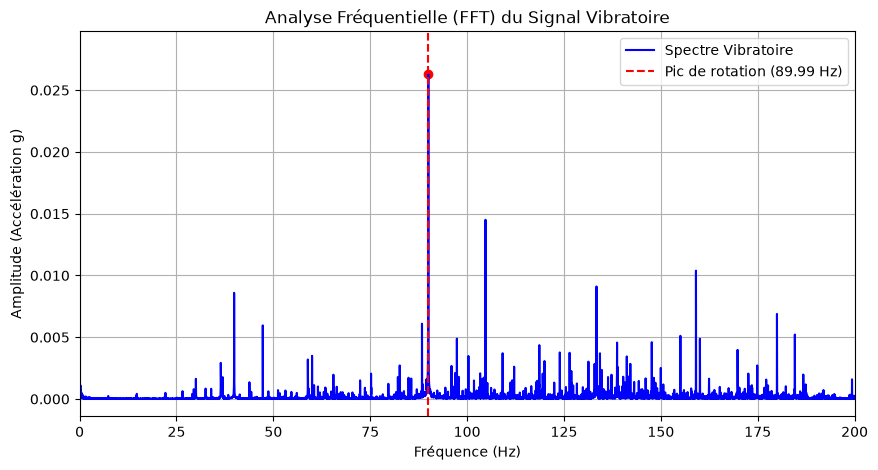

In [14]:


# ==========================================
# 3. CALCUL DE LA FFT (SPECTRE FRÉQUENTIEL)
# ==========================================
# Calcul de la transformée de Fourier
fft_vals = np.fft.fft(signal)

# Fréquences associées à chaque point de la FFT
freqs = np.fft.fftfreq(N, 1/fs)

# On ne conserve que la moitié positive du spectre (symétrie de la FFT)
half_N = N // 2
freqs_pos = freqs[:half_N]

# Calcul de l'amplitude réelle (normalisation)
amplitudes = (2.0 / N) * np.abs(fft_vals[:half_N])

# ==========================================
# 4. RECHERCHE DE LA FRÉQUENCE DE ROTATION (1X)
# ==========================================
# On exclut la composante continue (0 Hz) pour éviter les erreurs de décalage (offset)
# On cherche le pic maximal entre, par exemple, 10 Hz et 100 Hz (zone typique d'un moteur)
indice_min_recherche = np.searchsorted(freqs_pos, 10)
indice_max_recherche = np.searchsorted(freqs_pos, 100)

# Trouver l'indice du pic maximal dans cette zone restreinte
indice_pic = np.argmax(amplitudes[indice_min_recherche:indice_max_recherche]) + indice_min_recherche

f_rotation = freqs_pos[indice_pic]
amplitude_pic = amplitudes[indice_pic]

# Conversion de la fréquence (Hz) en vitesse de rotation (tr/min)
vitesse_rpm = f_rotation * 60

print("\n--- RÉSULTATS DE L'ANALYSE ---")
print(f"Fréquence de rotation détectée (1X) : {f_rotation:.2f} Hz")
print(f"Vitesse de rotation calculée        : {vitesse_rpm:.1f} tr/min")

# ==========================================
# 5. AFFICHAGE DU GRAPHIQUE (SPECTRE)
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(freqs_pos, amplitudes, label='Spectre Vibratoire', color='b')
plt.axvline(x=f_rotation, color='r', linestyle='--', label=f'Pic de rotation ({f_rotation:.2f} Hz)')
plt.scatter(f_rotation, amplitude_pic, color='r', marker='o')

plt.title("Analyse Fréquentielle (FFT) du Signal Vibratoire")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude (Accélération g)")
plt.xlim(0, 200)  # Zoom sur les basses fréquences pour mieux voir la rotation
plt.grid(True)
plt.legend()
plt.show()

In [15]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# ==========================================
# 1. CHARGEMENT DES DONNÉES
# ==========================================
# Charger le fichier MAT téléchargé
chemin = r"C:\Users\ReMarkt\Documents\0_PROJET_SCIENTIST\Data_CWRU\110.mat"
mat_data = loadmat(chemin)

# Extraire le signal vibratoire (ajuster le nom de la clé si nécessaire)
# Dans votre fichier, la variable s'appelle 'X110_DE_time'
signal = mat_data['X110_DE_time'].flatten()

# ==========================================
# 2. CONFIGURATION DES PARAMÈTRES DU SIGNAL
# ==========================================
# Fréquence d'échantillonnage théorique (en Hz)
# Note : 12000 Hz est la valeur standard pour les données CWRU (Drive End data)
fs = 48000  

# Nombre de points dans le signal
N = len(signal)

# Durée totale du signal en secondes
duree = N / fs

print(f"Nombre de points de mesure : {N}")
print(f"Durée du signal analysé : {duree:.2f} secondes")

# ==========================================
# 3. CALCUL DE LA FFT (SPECTRE FRÉQUENTIEL)
# ==========================================
# Calcul de la transformée de Fourier
fft_vals = np.fft.fft(signal)

# Fréquences associées à chaque point de la FFT
freqs = np.fft.fftfreq(N, 1/fs)

# On ne conserve que la moitié positive du spectre (symétrie de la FFT)
half_N = N // 2
freqs_pos = freqs[:half_N]

# Calcul de l'amplitude réelle (normalisation)
amplitudes = (2.0 / N) * np.abs(fft_vals[:half_N])

# ==========================================
# 4. RECHERCHE DE LA FRÉQUENCE DE ROTATION (1X)
# ==========================================
# On exclut la composante continue (0 Hz) pour éviter les erreurs de décalage (offset)
# On cherche le pic maximal entre, par exemple, 10 Hz et 100 Hz (zone typique d'un moteur)
indice_min_recherche = np.searchsorted(freqs_pos, 10)
indice_max_recherche = np.searchsorted(freqs_pos, 100)

# Trouver l'indice du pic maximal dans cette zone restreinte
indice_pic = np.argmax(amplitudes[indice_min_recherche:indice_max_recherche]) + indice_min_recherche

f_rotation = freqs_pos[indice_pic]
amplitude_pic = amplitudes[indice_pic]

# Conversion de la fréquence (Hz) en vitesse de rotation (tr/min)
vitesse_rpm = f_rotation * 60

print("\n--- RÉSULTATS DE L'ANALYSE ---")
print(f"Fréquence de rotation détectée (1X) : {f_rotation:.2f} Hz")
print(f"Vitesse de rotation calculée        : {vitesse_rpm:.1f} tr/min")

# ==========================================
# 5. AFFICHAGE DU GRAPHIQUE (SPECTRE)
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(freqs_pos, amplitudes, label='Spectre Vibratoire', color='b')
plt.axvline(x=f_rotation, color='r', linestyle='--', label=f'Pic de rotation ({f_rotation:.2f} Hz)')
plt.scatter(f_rotation, amplitude_pic, color='r', marker='o')

plt.title("Analyse Fréquentielle (FFT) du Signal Vibratoire")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude (Accélération g)")
plt.xlim(0, 200)  # Zoom sur les basses fréquences pour mieux voir la rotation
plt.grid(True)
plt.legend()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\ReMarkt\\Documents\\0_PROJET_SCIENTIST\\Data_CWRU\\110.mat'